In [1]:
import pandas as pd
import os

os.chdir("..")
df = pd.read_csv('data/cleaned_members.csv')

y = df['death']
X = df.drop(columns=['death'])

print("death: ", y.shape)
print("data: ", X.shape)

death:  (89000,)
data:  (89000, 29)


Loading in the data

In [2]:
from sklearn.model_selection import train_test_split


X_train, X_test, y_train, y_test = train_test_split(
 X, y, test_size=0.2, stratify=y, random_state = 42)

print(f"Training rows: {X_train.shape[0]}")
print(f"Training rows: {X_test.shape[0]}")

Training rows: 71200
Training rows: 17800


In [3]:
import sys
import os
print(os.getcwd())
#sys.path.append("..")
from src.preprocessor import get_preprocessor

preprocessor = get_preprocessor()

C:\Users\AineC\4th Year\Machine Learning\Himalayan Expedition\Himalayan-survivors


Calls the preprocessor function in the python script. 

In [43]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
forest = RandomForestClassifier(
    n_estimators = 500,
    max_features = "sqrt",
    min_samples_leaf = 5,
    oob_score = True,
    n_jobs = -1,
    class_weight = "balanced",
    random_state=42
)

forest_pipeline = Pipeline(steps = [("preprocessor", preprocessor), ("classifier", forest)])
forest_pipeline.fit(X_train, y_train)



C:\Users\AineC\4th Year\Machine Learning\Himalayan Expedition\.venv\Lib\site-packages\sklearn\ensemble\_forest.py:589: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[bool](2,)","[False, True]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](29,)","['peakid','myear','mseason',...,'route_choice','oxygen_status','age']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,29
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthroug

I've created a random forest model. The 2 numerical features are scaled while the boolean/string ones are one hot encoded.

In [25]:
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

forest_predictions = forest_pipeline.predict(X_test)
forest_probability = forest_pipeline.predict_proba(X_test)[:,1]

print("--- Random Forest Results ---")
print(f"OOB Score (Internal validation): {forest.oob_score_:.4f}")
print("Accuracy:", accuracy_score(y_test, forest_predictions))
print("F1 Score:", f1_score(y_test, forest_predictions, average='macro'))
print("ROC-AUC:", roc_auc_score(y_test, forest_probability))

--- Random Forest Results ---
OOB Score (Internal validation): 0.7901
Accuracy: 0.8015730337078651
F1 Score: 0.48637988764890916
ROC-AUC: 0.8233530252889266


Then used the random forest pipeline to predict whether a climber survived the expedition or not. The Roc-AUC has improved greatly, by about 30%. However, both the F1 Score and Accuracy have dropped. This means that the model isn't just guessing the most common answer without taking any features into account like the baseline model was. The Accuracy probably dropped because now that the model isn't just guessing survived each time, its guessing that some climbers that survived actually died

In [62]:
from sklearn.ensemble import GradientBoostingClassifier

gb = GradientBoostingClassifier(
    n_estimators=200,
    learning_rate=0.1,
    max_depth=3,
    subsample=0.8,
    random_state=42
    )

gb_pipeline = Pipeline(steps=[("preprocessor", preprocessor), ("classifier", gb)])
gb_pipeline.fit(X_train, y_train)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[bool](2,)","[False, True]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](29,)","['peakid','myear','mseason',...,'route_choice','oxygen_status','age']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,29
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthroug

Created a gradient boosting model. Was originally planning to create a XGBoost one instead, however, that model doesn't accept sparse data. Altering the data so that it wasn't sparse wasn't feasible as it just slowed everything down and took up a lot of memory so I just changed the model I used.

In [63]:
gb_predictions = gb_pipeline.predict(X_test)
gb_probability = gb_pipeline.predict_proba(X_test)[:,1]

print("--- Gradient Boosting Results ---")
#print(f"OOB Score (Internal validation): {forest.oob_score_:.4f}")
print("Accuracy:", accuracy_score(y_test, gb_predictions))
print("F1 Score:", f1_score(y_test, gb_predictions, average='macro'))
print("ROC-AUC:", roc_auc_score(y_test, gb_probability))

--- Gradient Boosting Results ---
Accuracy: 0.9865168539325843
F1 Score: 0.5521590087115137
ROC-AUC: 0.6940716320033289


This isn't the best result. The ROC-AUC has gone up compared to the dummy version. As has the F1 score but its not as drastic a change as the random forest one. It also scores signigicantly lower on everything but the F1 score compared to the Logistic Regression. The results are after I played around with the number of estimators, the learning rate and the max depth, these are the best set of results I've managed to get, particularly the ROC-AUC. The XGBoost might have scored better results but as mentioned previously, that wasn't feasible. I think I'll choose Random Forest as my main model instead.

In [49]:
for i in range (100, 1000, 100):
    tuned_forest = RandomForestClassifier(
        n_estimators = i,
        max_features = "sqrt",
        min_samples_leaf = 6,
        oob_score = True,
        n_jobs = -1,
        class_weight = "balanced",
        random_state=42
    )

    tuned_forest_pipeline = Pipeline(steps = [("preprocessor", preprocessor), ("classifier", tuned_forest)])
    tuned_forest_pipeline.fit(X_train, y_train)

    tuned_forest_predictions = tuned_forest_pipeline.predict(X_test)
    tuned_forest_probability = tuned_forest_pipeline.predict_proba(X_test)[:,1]

    print("--- Tuned Random Forest Results ---")
    print("i:", i)
    print(f"OOB Score (Internal validation): {tuned_forest.oob_score_:.4f}")
    print("Accuracy:", accuracy_score(y_test, tuned_forest_predictions))
    print("F1 Score:", f1_score(y_test, tuned_forest_predictions, average='macro'))
    print("ROC-AUC:", roc_auc_score(y_test, tuned_forest_probability))



C:\Users\AineC\4th Year\Machine Learning\Himalayan Expedition\.venv\Lib\site-packages\sklearn\ensemble\_forest.py:589: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


--- Tuned Random Forest Results ---
i: 100
OOB Score (Internal validation): 0.7901
Accuracy: 0.7802247191011236
F1 Score: 0.4752360863362701
ROC-AUC: 0.811442532661265


C:\Users\AineC\4th Year\Machine Learning\Himalayan Expedition\.venv\Lib\site-packages\sklearn\ensemble\_forest.py:589: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


--- Tuned Random Forest Results ---
i: 200
OOB Score (Internal validation): 0.7901
Accuracy: 0.7920224719101123
F1 Score: 0.4809391925741779
ROC-AUC: 0.8170246598439168


C:\Users\AineC\4th Year\Machine Learning\Himalayan Expedition\.venv\Lib\site-packages\sklearn\ensemble\_forest.py:589: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


--- Tuned Random Forest Results ---
i: 300
OOB Score (Internal validation): 0.7901
Accuracy: 0.7934831460674158
F1 Score: 0.4809748745159939
ROC-AUC: 0.8177361807910934


... (8 outputs left out)

C:\Users\AineC\4th Year\Machine Learning\Himalayan Expedition\.venv\Lib\site-packages\sklearn\ensemble\_forest.py:589: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


--- Tuned Random Forest Results ---
i: 800
OOB Score (Internal validation): 0.7901
Accuracy: 0.7963483146067416
F1 Score: 0.4828406445720321
ROC-AUC: 0.8166913490829721


C:\Users\AineC\4th Year\Machine Learning\Himalayan Expedition\.venv\Lib\site-packages\sklearn\ensemble\_forest.py:589: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


--- Tuned Random Forest Results ---
i: 900
OOB Score (Internal validation): 0.7901
Accuracy: 0.7967415730337079
F1 Score: 0.483035165816725
ROC-AUC: 0.8169303219804033


I did 10 iterations of random forest to find out the most number of estimators that would give me the most best scores. I paid particular attention to the ROC-AUC as the Accuracy doesn't take into account whether the model correctly guesses if someone dies and the F1 score greatly penalises the model when it mislabels someone who actually died as someone who survived which isn't ideal as the dataset is very imbalanced. 400 seemed to be the one that gave the highest ROC-AUC score so I'll be using that.

In [50]:
for i in range (1, 10, 1):
    tuned_forest = RandomForestClassifier(
        n_estimators = 400,
        max_features = "sqrt",
        min_samples_leaf = i,
        oob_score = True,
        n_jobs = -1,
        class_weight = "balanced",
        random_state=42
    )

    tuned_forest_pipeline = Pipeline(steps = [("preprocessor", preprocessor), ("classifier", tuned_forest)])
    tuned_forest_pipeline.fit(X_train, y_train)

    tuned_forest_predictions = tuned_forest_pipeline.predict(X_test)
    tuned_forest_probability = tuned_forest_pipeline.predict_proba(X_test)[:,1]

    print("--- Tuned Random Forest Results ---")
    print("i:", i)
    print(f"OOB Score (Internal validation): {tuned_forest.oob_score_:.4f}")
    print("Accuracy:", accuracy_score(y_test, tuned_forest_predictions))
    print("F1 Score:", f1_score(y_test, tuned_forest_predictions, average='macro'))
    print("ROC-AUC:", roc_auc_score(y_test, tuned_forest_probability))



C:\Users\AineC\4th Year\Machine Learning\Himalayan Expedition\.venv\Lib\site-packages\sklearn\ensemble\_forest.py:589: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


--- Tuned Random Forest Results ---
i: 1
OOB Score (Internal validation): 0.7901
Accuracy: 0.9879775280898876
F1 Score: 0.6305311691556572
ROC-AUC: 0.853086749615288


C:\Users\AineC\4th Year\Machine Learning\Himalayan Expedition\.venv\Lib\site-packages\sklearn\ensemble\_forest.py:589: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


--- Tuned Random Forest Results ---
i: 2
OOB Score (Internal validation): 0.7901
Accuracy: 0.8497752808988764
F1 Score: 0.5097571482436573
ROC-AUC: 0.842389522878588


C:\Users\AineC\4th Year\Machine Learning\Himalayan Expedition\.venv\Lib\site-packages\sklearn\ensemble\_forest.py:589: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


--- Tuned Random Forest Results ---
i: 3
OOB Score (Internal validation): 0.7901
Accuracy: 0.8247752808988764
F1 Score: 0.49829530090511565
ROC-AUC: 0.8329250675208844


... (8 outputs left out)

C:\Users\AineC\4th Year\Machine Learning\Himalayan Expedition\.venv\Lib\site-packages\sklearn\ensemble\_forest.py:589: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


--- Tuned Random Forest Results ---
i: 8
OOB Score (Internal validation): 0.7901
Accuracy: 0.7819101123595505
F1 Score: 0.47539251723493603
ROC-AUC: 0.8062999536775328


C:\Users\AineC\4th Year\Machine Learning\Himalayan Expedition\.venv\Lib\site-packages\sklearn\ensemble\_forest.py:589: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


--- Tuned Random Forest Results ---
i: 9
OOB Score (Internal validation): 0.7901
Accuracy: 0.7729775280898876
F1 Score: 0.47180162972965123
ROC-AUC: 0.800509277251743


I also tested the scores given the minimum number of samples per leaf. The ROC-AUC was highest when min_leaf was 1.

In [57]:
best_roc = 0.5 #dummy result
best_i = None
best_j = None
for i in range (100, 1000, 100):
    for j in range(1, 5, 1):
        tuned_forest = RandomForestClassifier(
        n_estimators = i,
        max_features = "sqrt",
        min_samples_leaf = j,
        oob_score = True,
        n_jobs = -1,
        class_weight = "balanced",
        random_state=42
        )

        tuned_forest_pipeline = Pipeline(steps = [("preprocessor", preprocessor), ("classifier", tuned_forest)])
        tuned_forest_pipeline.fit(X_train, y_train)

        tuned_forest_predictions = tuned_forest_pipeline.predict(X_test)
        tuned_forest_probability = tuned_forest_pipeline.predict_proba(X_test)[:,1]
        
        if roc_auc_score(y_test, tuned_forest_probability) > best_roc:
            best_roc = roc_auc_score(y_test, tuned_forest_probability)
            best_i = i
            best_j = j 
            print("NEW BEST")
            print("i:", i)
            print("j:", j)
            print("ROC-AUC:", roc_auc_score(y_test, tuned_forest_probability))



C:\Users\AineC\4th Year\Machine Learning\Himalayan Expedition\.venv\Lib\site-packages\sklearn\ensemble\_forest.py:589: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


NEW BEST
i: 100
j: 1
ROC-AUC: 0.8405030109603668


C:\Users\AineC\4th Year\Machine Learning\Himalayan Expedition\.venv\Lib\site-packages\sklearn\ensemble\_forest.py:589: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(
C:\Users\AineC\4th Year\Machine Learning\Himalayan Expedition\.venv\Lib\site-packages\sklearn\ensemble\_forest.py:589: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(
C:\Users\AineC\4th Year\Machine Learning\Himalayan Expedition\.venv\Lib\site-packages\sklearn\ensemble\_forest.py:589: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(
C:\Users\AineC\4th Year\Machine Learning\Himalayan Expedition\.venv\Lib\site-packages\sklearn\ensemble\_forest.py:589: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute 

NEW BEST
i: 200
j: 1
ROC-AUC: 0.8472276199673386


C:\Users\AineC\4th Year\Machine Learning\Himalayan Expedition\.venv\Lib\site-packages\sklearn\ensemble\_forest.py:589: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(
C:\Users\AineC\4th Year\Machine Learning\Himalayan Expedition\.venv\Lib\site-packages\sklearn\ensemble\_forest.py:589: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(
C:\Users\AineC\4th Year\Machine Learning\Himalayan Expedition\.venv\Lib\site-packages\sklearn\ensemble\_forest.py:589: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(
C:\Users\AineC\4th Year\Machine Learning\Himalayan Expedition\.venv\Lib\site-packages\sklearn\ensemble\_forest.py:589: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute 

NEW BEST
i: 300
j: 1
ROC-AUC: 0.8496090069719239


C:\Users\AineC\4th Year\Machine Learning\Himalayan Expedition\.venv\Lib\site-packages\sklearn\ensemble\_forest.py:589: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(
C:\Users\AineC\4th Year\Machine Learning\Himalayan Expedition\.venv\Lib\site-packages\sklearn\ensemble\_forest.py:589: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(
C:\Users\AineC\4th Year\Machine Learning\Himalayan Expedition\.venv\Lib\site-packages\sklearn\ensemble\_forest.py:589: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(
C:\Users\AineC\4th Year\Machine Learning\Himalayan Expedition\.venv\Lib\site-packages\sklearn\ensemble\_forest.py:589: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute 

NEW BEST
i: 400
j: 1
ROC-AUC: 0.853086749615288


C:\Users\AineC\4th Year\Machine Learning\Himalayan Expedition\.venv\Lib\site-packages\sklearn\ensemble\_forest.py:589: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(
C:\Users\AineC\4th Year\Machine Learning\Himalayan Expedition\.venv\Lib\site-packages\sklearn\ensemble\_forest.py:589: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(
C:\Users\AineC\4th Year\Machine Learning\Himalayan Expedition\.venv\Lib\site-packages\sklearn\ensemble\_forest.py:589: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(
C:\Users\AineC\4th Year\Machine Learning\Himalayan Expedition\.venv\Lib\site-packages\sklearn\ensemble\_forest.py:589: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute 

NEW BEST
i: 500
j: 1
ROC-AUC: 0.8532507674612148


C:\Users\AineC\4th Year\Machine Learning\Himalayan Expedition\.venv\Lib\site-packages\sklearn\ensemble\_forest.py:589: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(
C:\Users\AineC\4th Year\Machine Learning\Himalayan Expedition\.venv\Lib\site-packages\sklearn\ensemble\_forest.py:589: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(
C:\Users\AineC\4th Year\Machine Learning\Himalayan Expedition\.venv\Lib\site-packages\sklearn\ensemble\_forest.py:589: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(
C:\Users\AineC\4th Year\Machine Learning\Himalayan Expedition\.venv\Lib\site-packages\sklearn\ensemble\_forest.py:589: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute 

I decided to merge the tuning of the two parameters together just in case, as I ran the model with 1 as the min_samples_leaf and 500 as the number of estimators and it actually had a greater ROC-AUC score than min_samples_leaf = 1 and n_estimators=400. After running this it turns out that is actually the variation of the two parameters that gives the highest ROC-AUC score

In [67]:
chosen_model = RandomForestClassifier(
    n_estimators = 500,
    max_features = "sqrt",
    min_samples_leaf = 1,
    oob_score = True,
    n_jobs = -1,
    class_weight = "balanced",
    random_state=42
)

chosen_pipeline = Pipeline(steps = [("preprocessor", preprocessor), ("classifier", chosen_model)])
chosen_pipeline.fit(X_train, y_train)
chosen_predictions = chosen_pipeline.predict(X_test)
chosen_probability = chosen_pipeline.predict_proba(X_test)[:,1]
print("--- Chosen Random Forest Results ---")
print("i:", i)
print(f"OOB Score (Internal validation): {chosen_model.oob_score_:.4f}")
print("Accuracy:", accuracy_score(y_test, chosen_predictions))
print("F1 Score:", f1_score(y_test, chosen_predictions, average='macro'))
print("ROC-AUC:", roc_auc_score(y_test, chosen_probability))


C:\Users\AineC\4th Year\Machine Learning\Himalayan Expedition\.venv\Lib\site-packages\sklearn\ensemble\_forest.py:589: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


--- Chosen Random Forest Results ---
i: 100
OOB Score (Internal validation): 0.9854
Accuracy: 0.987808988764045
F1 Score: 0.631606741484089
ROC-AUC: 0.8532507674612148


This result is very good. All three scores are higher than the dummy, logistic regression and gradient booster model scores. 

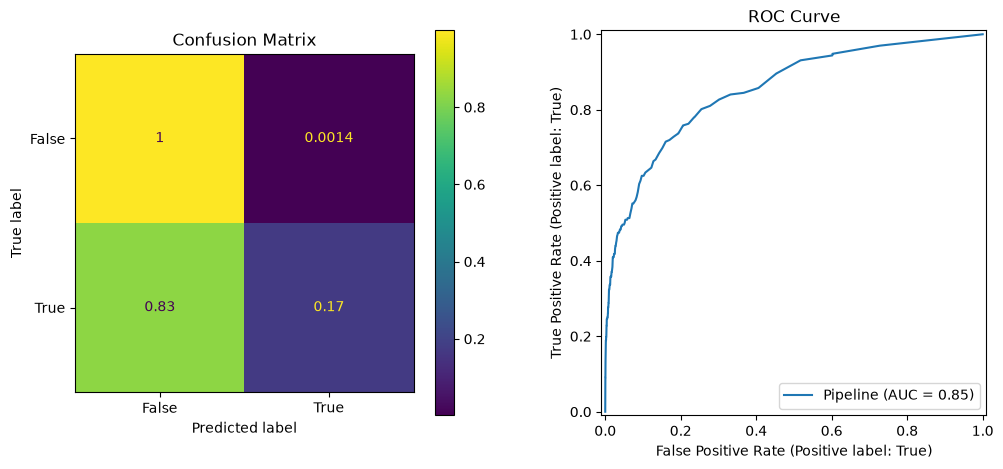

In [77]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_estimator(
    chosen_pipeline, X_test, y_test, 
    ax=ax[0],
    normalize = "true")
ax[0].set_title("Confusion Matrix")

RocCurveDisplay.from_estimator(
    chosen_pipeline, X_test, y_test, 
    ax=ax[1])
ax[1].set_title("ROC Curve")


plt.show()

The confusion matrix shows that close to 100% of survivors are correctly predicted. It probably shows 1 because the percentage of climbers the model incorrectly predicted to have died is so small (0.0014). The model is correctly predicting 17 percent of the deaths which isn't ideal. I think the class imbalance probably had a hand in this as 98% survived so its still more likely to guess that someone lived.

The ROC Curve 